# Jute leaf disease — ICCIT 2026 revision (all-in-one notebook)

One notebook = both of your old notebooks (ViT / hybrid + Swin-Tiny / EfficientNetB0) **plus** the reviewer-requested additions.
Everything trains with **the same 5 seeds for all four models**, results are **cached to disk**, so if Kaggle stops the session just press *Run all* again and finished runs are skipped.

**Before the real run:** set `QUICK_TEST = True` in section 0 and *Run all* once (2 epochs, 1 seed). It exercises every cell end to end. Then set it back to `False`.

| Section | What it does | Reviewer comment it answers |
|---|---|---|
| 1 | data + split check | provenance / reproducibility |
| 2 | picks 24 test images for lesion annotation (optional) | R1/R7: quantitative localization |
| 3 | model definitions (plain ViT, hybrid, Swin-T, EffNet-B0, ablation variants) | — |
| 4 | parameters, FLOPs, latency table | R7: computational cost |
| 5 | 5 seeds x 4 models | R1/R7: unbalanced seeds, small test set |
| 6 | mean±std table, Wilson CI, **McNemar** | R7: paired test, R1: cautious interpretation |
| 7 | duplicate / leakage check (pHash) | R1: duplicates, leakage |
| 8 | Grad-CAM + deletion/insertion + concentration (+ annotated overlap if provided) | R1/R7: quantitative interpretability |
| 9 | ablation of the attention module (r = 1, 2, 8, SE-gate) | R1/R7: novelty |
| 10 | optional 5-fold CV | R1/R7: CV |
| 11 | figures for the paper + export zip | — |

In [2]:
!pip -q install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [1]:
!find /kaggle/input -name "*.json" | head -3

/kaggle/input/datasets/muhammadtasibahasan/to-annotate/to_annotate/Dieback-188.json
/kaggle/input/datasets/muhammadtasibahasan/to-annotate/to_annotate/Dieback-194.json
/kaggle/input/datasets/muhammadtasibahasan/to-annotate/to_annotate/Dieback-216.json


In [5]:
# =====================================================================
# 0. CONFIG  -- the only cell you normally need to edit
# =====================================================================
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"   # must be set before torch is imported

QUICK_TEST = False   # True => 2 epochs, 1 seed, 1 ablation variant: smoke-test the WHOLE notebook first

# ---- experiment design -------------------------------------------------------------
SEEDS             = [42, 123, 2024, 7, 2025]       # identical seeds for ALL four models
MAIN_MODELS       = ["plainvit", "lightattn", "swintiny", "efficientnetb0"]
RUN_ABLATION      = True
ABLATION_SEEDS    = [42, 123, 2024]                # CHANGED: 3 seeds for the ablation variants
ABLATION_VARIANTS = ["abl_fullwidth_r1", "abl_r2", "abl_r8", "abl_se_gate"]
RUN_CV            = False                          # optional stratified k-fold CV (adds 4 x CV_FOLDS runs)
CV_FOLDS          = 5

# ---- training protocol (as in the submitted paper) -----------------------------------
IMG_SIZE = 224; BATCH_SIZE = 64; MAX_EPOCHS = 100
LEARNING_RATE = 3e-5; WEIGHT_DECAY = 0.01
EARLY_STOP_PATIENCE = 10; EARLY_STOP_MIN_DELTA = 5e-4
USE_AMP = True    # fp16 mixed precision, ~2-3x faster on a T4. Say so in the paper, or set False for fp32.

# ---- paths (Kaggle) -----------------------------------------------------------
DATA_DIR  = "/kaggle/input/datasets/muhammadtasibahasan/jute-disease-fmulseed/Jute Diesease Dataset"
SPLIT_CSV = "/kaggle/input/datasets/muhammadtasibahasan/dataset98/dataset_split.csv"
WORK      = "/kaggle/working/jute_revision"
ANNOT_DIR = "/kaggle/input/datasets/muhammadtasibahasan/to-annotate/to_annotate"   # CHANGED: your LabelMe .json folder
N_ANNOT_PER_CLASS = 6   # keep at 6 (it decides which 24 images were chosen for annotation)

classes = ["Fresh", "Stem Soft Rot", "Mosaic", "Holed", "Dieback"]   # same order as the paper
N_LATENCY_RUNS = 200

if QUICK_TEST:
    SEEDS = [42]; MAX_EPOCHS = 2; ABLATION_SEEDS = [42]; ABLATION_VARIANTS = ["abl_r8"]
    N_LATENCY_RUNS = 20; CV_FOLDS = 2
    WORK = WORK + "_quick"

RUN_DIR  = f"{WORK}/runs";  FIG_DIR = f"{WORK}/figures";  TAB_DIR = f"{WORK}/tables"
CKPT_DIR = f"{WORK}_ckpt"          # checkpoints are kept OUT of the export zip
for d in (RUN_DIR, FIG_DIR, TAB_DIR, CKPT_DIR):
    os.makedirs(d, exist_ok=True)
print("QUICK_TEST =", QUICK_TEST, "| seeds =", SEEDS, "| outputs ->", WORK)

# NEW: safety check, should print 23 (you annotated 23 images)
import glob
print("annotation .json files found:", len(glob.glob(os.path.join(ANNOT_DIR, "*.json"))) if ANNOT_DIR else "ANNOT_DIR not set")

QUICK_TEST = False | seeds = [42, 123, 2024, 7, 2025] | outputs -> /kaggle/working/jute_revision
annotation .json files found: 23


In [6]:
import time, random, json, math, shutil, itertools, warnings, hashlib
import numpy as np, pandas as pd
from PIL import Image, ImageDraw
from tqdm.auto import tqdm
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

import torch, torch.nn as nn, torch.nn.functional as F, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
import torchvision.transforms.functional as TF
from transformers import ViTModel

from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix)

warnings.filterwarnings("ignore", message=".*non-deterministic.*")
warnings.filterwarnings("ignore", category=FutureWarning)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ON = bool(USE_AMP and device.type == "cuda")
print("device:", device, "| GPU:", torch.cuda.get_device_name() if device.type == "cuda" else "none", "| AMP:", AMP_ON)

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device: cuda | GPU: Tesla T4 | AMP: True


In [7]:
# =====================================================================
# Pure-python helper functions (stats, hashing, masks). No torch needed.
# =====================================================================
from scipy import stats
from scipy.integrate import trapezoid
from scipy.fft import dctn

def wilson_ci(k, n, z=1.96):
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

def mcnemar_exact(correct_a, correct_b):
    """Exact two-sided McNemar test on paired per-image correctness. Returns (a_only_right, b_only_right, p)."""
    a = np.asarray(correct_a, bool); b = np.asarray(correct_b, bool)
    n_a = int(np.sum(a & ~b)); n_b = int(np.sum(~a & b)); n = n_a + n_b
    p = 1.0 if n == 0 else float(stats.binomtest(min(n_a, n_b), n, 0.5, alternative="two-sided").pvalue)
    return n_a, n_b, p

def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); m = len(p)
    adj = np.empty(m); running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * p[idx]); adj[idx] = min(1.0, running)
    return adj

def boot_ci(x, n_boot=5000, seed=0, alpha=0.05):
    x = np.asarray(x, float); rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(x), size=(n_boot, len(x)))
    m = x[idx].mean(1)
    return float(np.percentile(m, 100 * alpha / 2)), float(np.percentile(m, 100 * (1 - alpha / 2)))

def paired_wilcoxon(a, b):
    a = np.asarray(a, float); b = np.asarray(b, float)
    if np.allclose(a, b):
        return 1.0
    try:
        return float(stats.wilcoxon(a, b).pvalue)
    except ValueError:
        return 1.0

def phash64(path):
    img = Image.open(path).convert("L").resize((32, 32), Image.Resampling.LANCZOS)
    d = dctn(np.asarray(img, dtype=np.float64), type=2, norm="ortho")[:8, :8].flatten()
    return d > np.median(d[1:])          # 64 bits

def hamming_matrix(bits):
    B = bits.astype(np.float32)
    same = B @ B.T + (1 - B) @ (1 - B).T
    return np.rint(bits.shape[1] - same).astype(np.int32)

def topk_masks(cam, steps=20, seed=0):
    """Rank pixels by CAM value (ties broken by tiny fixed noise). Returns fractions and boolean masks (steps+1, H, W)
    where masks[k] marks the top fractions[k] of pixels."""
    H, W = cam.shape; P = H * W
    rng = np.random.default_rng(seed)
    flat = cam.reshape(-1).astype(np.float64) + 1e-9 * rng.random(P)
    rank = np.empty(P, dtype=np.int64)
    rank[np.argsort(-flat, kind="stable")] = np.arange(P)
    fr = np.linspace(0, 1, steps + 1)
    thr = np.round(fr * P).astype(np.int64)
    return fr, (rank[None, :] < thr[:, None]).reshape(steps + 1, H, W)

def cam_concentration(cam, top_frac=0.10):
    """(share of CAM mass in the top `top_frac` pixels, normalised entropy). Higher share / lower entropy = tighter map."""
    c = np.clip(np.asarray(cam, np.float64), 0, None).reshape(-1); s = c.sum()
    if s <= 0:
        return 0.0, 1.0
    p = c / s; k = max(1, int(round(top_frac * len(c))))
    top = np.sort(c)[::-1][:k].sum() / s
    ent = -(p[p > 0] * np.log(p[p > 0])).sum() / np.log(len(c))
    return float(top), float(ent)

def cam_vs_mask(cam, mask):
    """(share of CAM mass inside lesion mask, pointing-game hit, lift = mass share / mask area share)."""
    cam = np.clip(np.asarray(cam, np.float64), 0, None); mask = np.asarray(mask, bool)
    mass = float(cam[mask].sum() / max(cam.sum(), 1e-12))
    hit = float(mask.reshape(-1)[int(np.argmax(cam))])
    return mass, hit, mass / max(mask.mean(), 1e-12)

def labelme_mask(json_path, size=224):
    """LabelMe .json (rectangles and/or polygons) -> boolean mask at size x size (same non-aspect resize as the pipeline)."""
    d = json.load(open(json_path))
    W = d.get("imageWidth"); H = d.get("imageHeight")
    if not W or not H:
        raise ValueError(f"{json_path}: no imageWidth/imageHeight")
    sx, sy = size / W, size / H
    m = Image.new("L", (size, size), 0); dr = ImageDraw.Draw(m)
    for s in d["shapes"]:
        pts = [(x * sx, y * sy) for x, y in s["points"]]
        if s.get("shape_type") == "rectangle":
            (x1, y1), (x2, y2) = pts[0], pts[1]
            dr.rectangle([min(x1, x2), min(y1, y2), max(x1, x2), max(y1, y2)], fill=1)
        elif len(pts) >= 3:
            dr.polygon(pts, fill=1)
    return np.array(m, dtype=bool)

def fmt_ms(x, sd, nd=2):
    return f"{x:.{nd}f} ± {sd:.{nd}f}"

## 1. Data and the fixed split

In [ ]:
split_df = pd.read_csv(SPLIT_CSV)
split_df["full_path"] = split_df["relative_path"].apply(lambda r: os.path.join(DATA_DIR, r))

missing = [p for p in split_df["full_path"] if not os.path.exists(p)]
assert not missing, f"{len(missing)} files missing, e.g. {missing[:3]}  -> check DATA_DIR"
# class-order sanity check: folder name must equal classes[label] for every row (a wrong order silently ruins confusion matrices)
bad = [(p, l) for p, l in zip(split_df["full_path"], split_df["label"]) if os.path.basename(os.path.dirname(p)) != classes[int(l)]]
assert not bad, f"label/class-folder mismatch, e.g. {bad[:3]}  -> fix the `classes` list order"

def sel(name):
    d = split_df[split_df["split"] == name]
    return d["full_path"].values, d["label"].values
X_train, y_train = sel("train"); X_val, y_val = sel("val"); X_test, y_test = sel("test")
print(f"Train {len(X_train)} | Val {len(X_val)} | Test {len(X_test)}")
print(pd.crosstab(split_df["split"], split_df["label"].map(lambda i: classes[int(i)])).to_string())

# Pre-load every image ONCE, resized exa

In [ ]:
tly like the original pipeline (Resize((224,224)) then /255).
# Identical pixel values, but removes JPEG decoding from every epoch.
_resize = transforms.Resize((IMG_SIZE, IMG_SIZE))
def load_u8(path):
    img = _resize(Image.open(path).convert("RGB"))
    return torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1).contiguous()
IMG_CACHE = {p: load_u8(p) for p in tqdm(split_df["full_path"].values, desc="caching images")}

class JuteDataset(Dataset):
    def __init__(self, paths, labels, augment=False):
        self.x = torch.stack([IMG_CACHE[p] for p in paths])
        self.y = torch.as_tensor(np.asarray(labels), dtype=torch.long)
        self.augment = augment
        self.aug = transforms.Compose([                      # same as the submitted paper
            transforms.RandomHorizontalFlip(),
            transforms.RandomVerticalFlip(),
            transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1)])
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        img = self.x[i].float().div_(255.0)
        if self.augment:
            img = self.aug(img)
        return img, self.y[i]

def make_loaders(Xtr, ytr, Xva, yva, Xte, yte, seed):
    set_seed(seed)
    cw = compute_class_weight("balanced", classes=np.unique(ytr), y=ytr)
    cw = torch.tensor(cw, dtype=torch.float).to(device)
    g = torch.Generator(); g.manual_seed(seed)
    tr = DataLoader(JuteDataset(Xtr, ytr, True),  batch_size=BATCH_SIZE, shuffle=True, generator=g)
    va = DataLoader(JuteDataset(Xva, yva, False), batch_size=BATCH_SIZE, shuffle=False)
    te = DataLoader(JuteDataset(Xte, yte, False), batch_size=BATCH_SIZE, shuffle=False)
    return tr, va, te, cw

def build_dataloaders(seed):
    return make_loaders(X_train, y_train, X_val, y_val, X_test, y_test, seed)

TEST_IMGS = torch.stack([IMG_CACHE[p] for p in X_test]).float().div(255.0)   # (139,3,224,224) for Grad-CAM etc.
print("test tensor:", tuple(TEST_IMGS.shape))

Train 973 | Val 278 | Test 139
label  Dieback  Fresh  Holed  Mosaic  Stem Soft Rot
split                                              
test        30     28     30      24             27
train      210    196    210     168            189
val         60     56     60      48             54


caching images:   0%|          | 0/1390 [00:00<?, ?it/s]

test tensor: (139, 3, 224, 224)


## 2. Lesion annotation set (optional, ~30-40 min of work)

Run **sections 0-2 only** first (*Run all above*). This writes `to_annotate.zip` (24 test images: 6 per diseased class; Fresh leaves have no lesion).
Annotate them with **LabelMe** (`pip install labelme`, then `labelme`): draw one rectangle or polygon around the diseased tissue per image, save as `.json` next to each image.
Upload the folder of `.json` files as a Kaggle dataset, set `ANNOT_DIR` in section 0 to that folder, and run the whole notebook. If `ANNOT_DIR = None` the annotation metrics are skipped and everything else still runs.

In [9]:
rng = np.random.RandomState(0)
test_df = split_df[split_df["split"] == "test"].reset_index(drop=True)
cand = []
for ci in range(1, len(classes)):                               # skip Fresh (no lesion)
    idx = np.where(test_df["label"].values == ci)[0]
    take = np.sort(rng.choice(idx, size=min(N_ANNOT_PER_CLASS, len(idx)), replace=False))
    cand += [(int(i), classes[ci], test_df.loc[i, "full_path"]) for i in take]
cand_df = pd.DataFrame(cand, columns=["test_index", "class", "path"])
ann_dir = f"{WORK}/to_annotate"; os.makedirs(ann_dir, exist_ok=True)
for _, r in cand_df.iterrows():
    shutil.copy(r["path"], os.path.join(ann_dir, os.path.basename(r["path"])))
cand_df.to_csv(f"{TAB_DIR}/annotation_candidates.csv", index=False)
shutil.make_archive(f"{WORK}/to_annotate", "zip", ann_dir)
print(cand_df[["test_index", "class"]].value_counts("class").to_string())
print("-> download", f"{WORK}/to_annotate.zip", "and annotate with LabelMe (one rectangle/polygon per image, save .json)")

class
Dieback          6
Holed            6
Mosaic           6
Stem Soft Rot    6
-> download /kaggle/working/jute_revision/to_annotate.zip and annotate with LabelMe (one rectangle/polygon per image, save .json)


## 3. Models
Same four models as the paper, plus ablation variants of the attention module. `abl_fullwidth_r1` is the "full-width extra attention layer" that the paper uses as its motivation (r = 1 means Q/K are not reduced).

In [10]:
VIT_NAME = "google/vit-base-patch16-224-in21k"

class PlainViT(nn.Module):
    def __init__(self, model_name, num_classes):
        super().__init__()
        self.vit = ViTModel.from_pretrained(model_name)
        self.classifier = nn.Linear(self.vit.config.hidden_size, num_classes)
    def forward(self, pixel_values):
        return self.classifier(self.vit(pixel_values=pixel_values).last_hidden_state[:, 0])

class LightweightTokenAttention(nn.Module):
    """Single-head self-attention on the ViT output tokens. Q/K projected to hidden/reduction, V kept at full width."""
    def __init__(self, hidden_size, reduction=4):
        super().__init__()
        r = max(hidden_size // reduction, 1)
        self.query = nn.Linear(hidden_size, r); self.key = nn.Linear(hidden_size, r)
        self.value = nn.Linear(hidden_size, hidden_size)
        self.scale = r ** -0.5; self.softmax = nn.Softmax(dim=-1)
        self.last_attn_weights = None
    def forward(self, x):
        Q, K, V = self.query(x), self.key(x), self.value(x)
        a = self.softmax(torch.bmm(Q, K.transpose(1, 2)) * self.scale)
        self.last_attn_weights = a.detach()
        return torch.bmm(a, V)

class SETokenGate(nn.Module):
    """Squeeze-and-excitation style channel gate on the tokens (a common cheap attention head, used as a comparator)."""
    def __init__(self, hidden_size, reduction=4):
        super().__init__()
        self.fc1 = nn.Linear(hidden_size, hidden_size // reduction)
        self.fc2 = nn.Linear(hidden_size // reduction, hidden_size)
        self.last_attn_weights = None
    def forward(self, x):
        g = torch.sigmoid(self.fc2(torch.relu(self.fc1(x.mean(dim=1)))))
        return x * g.unsqueeze(1)

class ViTWithLightAttention(nn.Module):
    def __init__(self, model_name, num_classes, dropout=0.1, reduction=4, head="lightattn"):
        super().__init__()
        self.backbone = ViTModel.from_pretrained(model_name)
        h = self.backbone.config.hidden_size
        self.light_attn = LightweightTokenAttention(h, reduction) if head == "lightattn" else SETokenGate(h, reduction)
        self.norm = nn.LayerNorm(h); self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(h, num_classes)
    def forward(self, pixel_values):
        tokens = self.backbone(pixel_values=pixel_values).last_hidden_state
        x = self.dropout(self.norm(tokens + self.light_attn(tokens)))
        return self.classifier(x[:, 0])

class SwinTinyBaseline(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.backbone = models.swin_t(weights=models.Swin_T_Weights.IMAGENET1K_V1)
        self.backbone.head = nn.Linear(self.backbone.head.in_features, num_classes)
    def forward(self, pixel_values): return self.backbone(pixel_values)

class EfficientNetBaseline(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.backbone = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        self.backbone.classifier[1] = nn.Linear(self.backbone.classifier[1].in_features, num_classes)
    def forward(self, pixel_values): return self.backbone(pixel_values)

def build_plain_vit_model(seed):  set_seed(seed); return PlainViT(VIT_NAME, len(classes)).to(device)
def build_model(seed, reduction=4, head="lightattn"):
    set_seed(seed); return ViTWithLightAttention(VIT_NAME, len(classes), 0.1, reduction, head).to(device)
def build_swin_model(seed):       set_seed(seed); return SwinTinyBaseline(len(classes)).to(device)
def build_efficientnet_model(seed): set_seed(seed); return EfficientNetBaseline(len(classes)).to(device)

MODEL_BUILDERS = {"plainvit": build_plain_vit_model, "lightattn": build_model,
                  "swintiny": build_swin_model, "efficientnetb0": build_efficientnet_model}
ABLATION_BUILDERS = {"abl_fullwidth_r1": lambda s: build_model(s, reduction=1),
                     "abl_r2":           lambda s: build_model(s, reduction=2),
                     "abl_r8":           lambda s: build_model(s, reduction=8),
                     "abl_se_gate":      lambda s: build_model(s, head="se")}
ALL_BUILDERS = {**MODEL_BUILDERS, **ABLATION_BUILDERS}
DISPLAY = {"plainvit": "Plain ViT-B/16", "lightattn": "Hybrid (ViT + token attn, r=4)", "swintiny": "Swin-Tiny",
           "efficientnetb0": "EfficientNetB0", "abl_fullwidth_r1": "ViT + full-width attn (r=1)",
           "abl_r2": "Hybrid r=2", "abl_r8": "Hybrid r=8", "abl_se_gate": "ViT + SE-style gate"}

## 4. Model cost: parameters, FLOPs, latency, checkpoint size
Latency is batch-1, fp32, on whatever GPU this session got (the GPU name is saved in the table). FLOPs are counted with PyTorch's `FlopCounterMode` (1 multiply-add = 2 FLOPs).

In [11]:
from torch.utils.flop_counter import FlopCounterMode

def measure_cost(tag, n_runs=N_LATENCY_RUNS, warmup=30):
    m = ALL_BUILDERS[tag](42).eval()
    params = sum(p.numel() for p in m.parameters())
    x1 = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=device)
    try:
        with torch.no_grad(), FlopCounterMode(display=False) as fc:
            m(x1)
        gflops = fc.get_total_flops() / 1e9
    except Exception as e:
        print("FLOP counter failed for", tag, e); gflops = float("nan")
    lat = []
    with torch.no_grad():
        for _ in range(warmup): m(x1)
        if device.type == "cuda": torch.cuda.synchronize()
        for _ in range(n_runs):
            if device.type == "cuda":
                s = torch.cuda.Event(enable_timing=True); e = torch.cuda.Event(enable_timing=True)
                s.record(); m(x1); e.record(); torch.cuda.synchronize(); lat.append(s.elapsed_time(e))
            else:
                t = time.perf_counter(); m(x1); lat.append((time.perf_counter() - t) * 1e3)
    size_mb = params * 4 / 1024**2
    del m; torch.cuda.empty_cache()
    q1, med, q3 = np.percentile(lat, [25, 50, 75])
    return dict(tag=tag, model=DISPLAY[tag], params_M=params / 1e6, GFLOPs=gflops,
                latency_ms_median=med, latency_ms_IQR=f"{q1:.2f}-{q3:.2f}", fp32_size_MB=size_mb)

cost_rows = [measure_cost(t) for t in MAIN_MODELS]
cost_df = pd.DataFrame(cost_rows)
cost_df["GPU"] = torch.cuda.get_device_name() if device.type == "cuda" else "cpu"
PARAMS = dict(zip(cost_df["tag"], cost_df["params_M"]))
extra = cost_df.set_index("tag").loc["lightattn", "params_M"] - cost_df.set_index("tag").loc["plainvit", "params_M"]
print(cost_df.drop(columns="tag").round(3).to_string(index=False))
print(f"\nToken-attention module adds {extra:.3f} M parameters = {100 * extra / PARAMS['plainvit']:.2f}% of the plain ViT")
cost_df.to_csv(f"{TAB_DIR}/table_cost.csv", index=False)

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:00<00:00, 181MB/s] 


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 134MB/s] 


                         model  params_M  GFLOPs  latency_ms_median latency_ms_IQR  fp32_size_MB      GPU
                Plain ViT-B/16    86.393  35.127             14.956    14.73-15.30       329.563 Tesla T4
Hybrid (ViT + token attn, r=4)    87.281  35.550             15.807    15.49-16.18       332.949 Tesla T4
                     Swin-Tiny    27.523   8.980             20.508    20.13-21.00       104.993 Tesla T4
                EfficientNetB0     4.014   0.769              8.655      8.50-8.88        15.312 Tesla T4

Token-attention module adds 0.887 M parameters = 1.03% of the plain ViT


## 5. Training: 5 seeds x 4 models (same protocol, same split)
Each finished run is stored in `runs/` (metrics, predictions, probabilities, training history). **Re-running the notebook skips finished runs.**
Checkpoints are kept only for plain ViT and the hybrid at the first seed (needed for Grad-CAM); the rest are deleted to save disk.

In [12]:
RUNS = {}          # (tag, seed) -> result dict

def compute_metrics(lbls, preds):
    pm, rm, fm, _ = precision_recall_fscore_support(lbls, preds, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(lbls, preds, average="weighted", zero_division=0)
    return dict(accuracy=float(accuracy_score(lbls, preds)), n_correct=int((np.asarray(lbls) == np.asarray(preds)).sum()),
                precision_macro=float(pm), recall_macro=float(rm), f1_macro=float(fm),
                precision_weighted=float(pw), recall_weighted=float(rw), f1_weighted=float(fw))

@torch.no_grad()
def predict(model, loader):
    model.eval(); P, L = [], []
    for imgs, y in loader:
        with torch.autocast("cuda", dtype=torch.float16, enabled=AMP_ON):
            out = model(imgs.to(device))
        P.append(torch.softmax(out.float(), 1).cpu().numpy()); L.append(y.numpy())
    probs = np.concatenate(P); return probs.argmax(1), probs, np.concatenate(L)

def fit(model, train_loader, val_loader, cw, run_name, ckpt_path):
    criterion = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    try:    scaler = torch.amp.GradScaler("cuda", enabled=AMP_ON)
    except Exception: scaler = torch.cuda.amp.GradScaler(enabled=AMP_ON)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc, best_val_loss, no_imp, epochs_run = -1.0, float("inf"), 0, 0
    for epoch in range(MAX_EPOCHS):
        model.train(); rl, rc, rt = 0.0, 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=AMP_ON):
                out = model(imgs); loss = criterion(out.float(), labels)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            rl += loss.item() * imgs.size(0); rc += (out.argmax(1) == labels).sum().item(); rt += labels.size(0)
        model.eval(); vl, vc, vt = 0.0, 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                with torch.autocast("cuda", dtype=torch.float16, enabled=AMP_ON):
                    out = model(imgs)
                vl += criterion(out.float(), labels).item() * imgs.size(0); vc += (out.argmax(1) == labels).sum().item(); vt += labels.size(0)
        tl, ta, vlo, va = rl / rt, rc / rt, vl / vt, vc / vt
        for k, v in zip(hist, (tl, vlo, ta, va)): hist[k].append(float(v))
        epochs_run = epoch + 1
        print(f"[{run_name}] ep {epochs_run:3d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vlo:.4f} acc {va:.4f}")
        if va > best_val_acc:
            best_val_acc = va; torch.save(model.state_dict(), ckpt_path)
        if vlo < best_val_loss - EARLY_STOP_MIN_DELTA: best_val_loss, no_imp = vlo, 0
        else: no_imp += 1
        if no_imp >= EARLY_STOP_PATIENCE:
            print(f"[{run_name}] early stop at epoch {epochs_run} (best val loss {best_val_loss:.4f}, best val acc {best_val_acc:.4f})"); break
    return hist, best_val_acc, epochs_run

def ckpt_path_of(run_name): return f"{CKPT_DIR}/{run_name}.pth"

def run_experiment(tag, seed, loaders_fn=None, run_name=None, keep=None):
    run_name = run_name or f"{tag}_seed{seed}"
    meta_p, npz_p = f"{RUN_DIR}/{run_name}.json", f"{RUN_DIR}/{run_name}.npz"
    if os.path.exists(meta_p) and os.path.exists(npz_p):
        meta = json.load(open(meta_p)); z = np.load(npz_p)
        print(f"[cached] {run_name}: acc {meta['metrics']['accuracy']*100:.2f}%")
        return dict(meta=meta, metrics=meta["metrics"], history=meta["history"], preds=z["preds"], probs=z["probs"], lbls=z["lbls"])
    keep = (seed == SEEDS[0] and tag in ("plainvit", "lightattn")) if keep is None else keep   # only Grad-CAM models need weights
    tr, va, te, cw = (loaders_fn or build_dataloaders)(seed)
    model = ALL_BUILDERS[tag](seed)
    ck = ckpt_path_of(run_name); t0 = time.time()
    hist, bva, ep = fit(model, tr, va, cw, run_name, ck)
    model.load_state_dict(torch.load(ck, map_location=device))
    preds, probs, lbls = predict(model, te)
    metrics = compute_metrics(lbls, preds)
    meta = dict(tag=tag, seed=seed, run_name=run_name, best_val_acc=bva, epochs_run=ep, train_seconds=round(time.time() - t0),
                amp=AMP_ON, metrics=metrics, history=hist)
    json.dump(meta, open(meta_p, "w")); np.savez(npz_p, preds=preds, probs=probs, lbls=lbls)
    if not keep and os.path.exists(ck): os.remove(ck)
    print(f"[done]   {run_name}: test acc {metrics['accuracy']*100:.2f}% | {meta['train_seconds']//60} min")
    del model; torch.cuda.empty_cache()
    return dict(meta=meta, metrics=metrics, history=hist, preds=preds, probs=probs, lbls=lbls)

def ensure_ckpt(tag, seed):
    """Grad-CAM needs the trained weights; if a cached run lost its checkpoint, retrain it once."""
    rn = f"{tag}_seed{seed}"
    if not os.path.exists(ckpt_path_of(rn)):
        for ext in ("json", "npz"):
            p = f"{RUN_DIR}/{rn}.{ext}"
            if os.path.exists(p): os.remove(p)
        RUNS[(tag, seed)] = run_experiment(tag, seed, keep=True)

def load_trained(tag, seed):
    ensure_ckpt(tag, seed)
    m = ALL_BUILDERS[tag](seed)
    m.load_state_dict(torch.load(ckpt_path_of(f"{tag}_seed{seed}"), map_location=device))
    return m.to(device).eval()

In [13]:
# MAIN EXPERIMENT. Seeds in the outer loop so that, if time runs out, every model has the same number of finished seeds.
for seed in SEEDS:
    for tag in MAIN_MODELS:
        RUNS[(tag, seed)] = run_experiment(tag, seed)
print("\nmain runs finished:", sorted(RUNS))

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[plainvit_seed42] ep   1 | train loss 1.3905 acc 0.7040 | val loss 1.1360 acc 0.9388
[plainvit_seed42] ep   2 | train loss 0.9824 acc 0.9353 | val loss 0.8091 acc 0.9532
[plainvit_seed42] ep   3 | train loss 0.7152 acc 0.9620 | val loss 0.6236 acc 0.9568
[plainvit_seed42] ep   4 | train loss 0.5656 acc 0.9794 | val loss 0.5241 acc 0.9820
[plainvit_seed42] ep   5 | train loss 0.4889 acc 0.9897 | val loss 0.4862 acc 0.9748
[plainvit_seed42] ep   6 | train loss 0.4484 acc 0.9949 | val loss 0.4564 acc 0.9784
[plainvit_seed42] ep   7 | train loss 0.4245 acc 0.9979 | val loss 0.4413 acc 0.9820
[plainvit_seed42] ep   8 | train loss 0.4135 acc 0.9990 | val loss 0.4351 acc 0.9856
[plainvit_seed42] ep   9 | train loss 0.4058 acc 0.9990 | val loss 0.4273 acc 0.9892
[plainvit_seed42] ep  10 | train loss 0.4009 acc 1.0000 | val loss 0.4280 acc 0.9856
[plainvit_seed42] ep  11 | train loss 0.3986 acc 1.0000 | val loss 0.4226 acc 0.9892
[plainvit_seed42] ep  12 | train loss 0.3964 acc 1.0000 | val los

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[lightattn_seed42] ep   1 | train loss 0.9737 acc 0.7225 | val loss 0.5663 acc 0.9353
[lightattn_seed42] ep   2 | train loss 0.5199 acc 0.9599 | val loss 0.4945 acc 0.9676
[lightattn_seed42] ep   3 | train loss 0.4765 acc 0.9764 | val loss 0.4803 acc 0.9748
[lightattn_seed42] ep   4 | train loss 0.4392 acc 0.9908 | val loss 0.4476 acc 0.9856
[lightattn_seed42] ep   5 | train loss 0.4228 acc 0.9959 | val loss 0.4419 acc 0.9820
[lightattn_seed42] ep   6 | train loss 0.4138 acc 0.9979 | val loss 0.4290 acc 0.9892
[lightattn_seed42] ep   7 | train loss 0.4070 acc 0.9990 | val loss 0.4274 acc 0.9892
[lightattn_seed42] ep   8 | train loss 0.4043 acc 1.0000 | val loss 0.4227 acc 0.9928
[lightattn_seed42] ep   9 | train loss 0.4031 acc 0.9990 | val loss 0.4194 acc 0.9964
[lightattn_seed42] ep  10 | train loss 0.4017 acc 1.0000 | val loss 0.4190 acc 0.9928
[lightattn_seed42] ep  11 | train loss 0.3998 acc 1.0000 | val loss 0.4158 acc 0.9928
[lightattn_seed42] ep  12 | train loss 0.3998 acc 1.00

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[plainvit_seed123] ep   1 | train loss 1.3941 acc 0.7061 | val loss 1.1589 acc 0.9209
[plainvit_seed123] ep   2 | train loss 1.0011 acc 0.9404 | val loss 0.8274 acc 0.9460
[plainvit_seed123] ep   3 | train loss 0.7186 acc 0.9661 | val loss 0.6248 acc 0.9640
[plainvit_seed123] ep   4 | train loss 0.5594 acc 0.9794 | val loss 0.5284 acc 0.9784
[plainvit_seed123] ep   5 | train loss 0.4798 acc 0.9918 | val loss 0.4878 acc 0.9748
[plainvit_seed123] ep   6 | train loss 0.4486 acc 0.9918 | val loss 0.4706 acc 0.9712
[plainvit_seed123] ep   7 | train loss 0.4290 acc 0.9928 | val loss 0.4470 acc 0.9820
[plainvit_seed123] ep   8 | train loss 0.4138 acc 0.9969 | val loss 0.4388 acc 0.9820
[plainvit_seed123] ep   9 | train loss 0.4059 acc 0.9979 | val loss 0.4350 acc 0.9856
[plainvit_seed123] ep  10 | train loss 0.4012 acc 0.9990 | val loss 0.4313 acc 0.9856
[plainvit_seed123] ep  11 | train loss 0.3989 acc 0.9990 | val loss 0.4341 acc 0.9820
[plainvit_seed123] ep  12 | train loss 0.3975 acc 0.99

... (10 outputs left out)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[plainvit_seed2025] ep   1 | train loss 1.3770 acc 0.7163 | val loss 1.1348 acc 0.9317
[plainvit_seed2025] ep   2 | train loss 0.9797 acc 0.9394 | val loss 0.8147 acc 0.9460
[plainvit_seed2025] ep   3 | train loss 0.7208 acc 0.9558 | val loss 0.6465 acc 0.9604
[plainvit_seed2025] ep   4 | train loss 0.5737 acc 0.9723 | val loss 0.5432 acc 0.9712
[plainvit_seed2025] ep   5 | train loss 0.4916 acc 0.9877 | val loss 0.4999 acc 0.9676
[plainvit_seed2025] ep   6 | train loss 0.4730 acc 0.9825 | val loss 0.4774 acc 0.9748
[plainvit_seed2025] ep   7 | train loss 0.4341 acc 0.9928 | val loss 0.4585 acc 0.9712
[plainvit_seed2025] ep   8 | train loss 0.4191 acc 0.9949 | val loss 0.4489 acc 0.9784
[plainvit_seed2025] ep   9 | train loss 0.4083 acc 0.9990 | val loss 0.4403 acc 0.9784
[plainvit_seed2025] ep  10 | train loss 0.4034 acc 0.9990 | val loss 0.4339 acc 0.9820
[plainvit_seed2025] ep  11 | train loss 0.4005 acc 0.9990 | val loss 0.4373 acc 0.9784
[plainvit_seed2025] ep  12 | train loss 0.3

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[lightattn_seed2025] ep   1 | train loss 0.9638 acc 0.7492 | val loss 0.5517 acc 0.9353
[lightattn_seed2025] ep   2 | train loss 0.5037 acc 0.9620 | val loss 0.4972 acc 0.9604
[lightattn_seed2025] ep   3 | train loss 0.4654 acc 0.9784 | val loss 0.4708 acc 0.9748
[lightattn_seed2025] ep   4 | train loss 0.4307 acc 0.9938 | val loss 0.4546 acc 0.9748
[lightattn_seed2025] ep   5 | train loss 0.4188 acc 0.9969 | val loss 0.4566 acc 0.9784
[lightattn_seed2025] ep   6 | train loss 0.4120 acc 0.9969 | val loss 0.4442 acc 0.9784
[lightattn_seed2025] ep   7 | train loss 0.4058 acc 1.0000 | val loss 0.4446 acc 0.9784
[lightattn_seed2025] ep   8 | train loss 0.4046 acc 0.9990 | val loss 0.4374 acc 0.9784
[lightattn_seed2025] ep   9 | train loss 0.4012 acc 1.0000 | val loss 0.4395 acc 0.9784
[lightattn_seed2025] ep  10 | train loss 0.4000 acc 1.0000 | val loss 0.4428 acc 0.9784
[lightattn_seed2025] ep  11 | train loss 0.3992 acc 1.0000 | val loss 0.4408 acc 0.9784
[lightattn_seed2025] ep  12 | tr

## 6. Results tables, Wilson intervals, McNemar

In [14]:
def agg(tag, key, scale=100):
    v = np.array([RUNS[(tag, s)]["metrics"][key] for s in SEEDS if (tag, s) in RUNS]) * scale
    return v.mean(), (v.std(ddof=1) if len(v) > 1 else 0.0), v

rows = []
for tag in MAIN_MODELS:
    n_seeds = sum((tag, s) in RUNS for s in SEEDS)
    am, asd, av = agg(tag, "accuracy")
    r0 = RUNS[(tag, SEEDS[0])]; lo, hi = wilson_ci(r0["metrics"]["n_correct"], len(r0["lbls"]))
    rows.append({"Model": DISPLAY[tag], "Params (M)": round(PARAMS[tag], 2), "Seeds": n_seeds,
                 "Acc % (mean±std)": fmt_ms(am, asd), "Acc range": f"{av.min():.2f}-{av.max():.2f}",
                 "Macro-P": fmt_ms(*agg(tag, "precision_macro")[:2]), "Macro-R": fmt_ms(*agg(tag, "recall_macro")[:2]),
                 "Macro-F1": fmt_ms(*agg(tag, "f1_macro")[:2]),
                 f"Seed-{SEEDS[0]} Acc %": round(100 * r0["metrics"]["accuracy"], 2),
                 f"Seed-{SEEDS[0]} 95% Wilson CI": f"[{100*lo:.2f}, {100*hi:.2f}]"})
main_df = pd.DataFrame(rows)
print(main_df.to_string(index=False))
main_df.to_csv(f"{TAB_DIR}/table_main_5seeds.csv", index=False)

all_runs_df = pd.DataFrame([{**{"model": t, "seed": s}, **RUNS[(t, s)]["metrics"], "epochs": RUNS[(t, s)]["meta"]["epochs_run"],
                             "best_val_acc": RUNS[(t, s)]["meta"]["best_val_acc"]} for (t, s) in sorted(RUNS)])
all_runs_df.to_csv(f"{TAB_DIR}/all_runs.csv", index=False)

# ---- Reviewer 1: "metrics and confusion matrices should be checked for consistency" -----------------------------------
print("\nSeed", SEEDS[0], "- macro vs weighted averages (the submitted Table I says 'macro' but weighted recall is always == accuracy):")
chk = all_runs_df[all_runs_df.seed == SEEDS[0]][["model", "accuracy", "precision_macro", "recall_macro", "f1_macro",
                                                 "precision_weighted", "recall_weighted", "f1_weighted"]]
print((chk.set_index("model") * 100).round(2).to_string())
for t in MAIN_MODELS:
    r = RUNS[(t, SEEDS[0])]; cm = confusion_matrix(r["lbls"], r["preds"])
    assert cm.trace() == r["metrics"]["n_correct"] and cm.sum() == len(r["lbls"])
print("confusion-matrix totals / accuracy consistency: OK")

                         Model  Params (M)  Seeds Acc % (mean±std)   Acc range      Macro-P      Macro-R     Macro-F1  Seed-42 Acc % Seed-42 95% Wilson CI
                Plain ViT-B/16       86.39      5     97.84 ± 0.00 97.84-97.84 97.91 ± 0.10 97.91 ± 0.05 97.88 ± 0.03          97.84        [93.85, 99.26]
Hybrid (ViT + token attn, r=4)       87.28      5     98.42 ± 0.32 97.84-98.56 98.49 ± 0.29 98.50 ± 0.32 98.46 ± 0.31          98.56        [94.91, 99.60]
                     Swin-Tiny       27.52      5     98.99 ± 0.39 98.56-99.28 99.05 ± 0.35 99.07 ± 0.37 99.03 ± 0.38          99.28        [96.04, 99.87]
                EfficientNetB0        4.01      5     98.56 ± 0.51 97.84-99.28 98.61 ± 0.48 98.67 ± 0.47 98.61 ± 0.49          98.56        [94.91, 99.60]

Seed 42 - macro vs weighted averages (the submitted Table I says 'macro' but weighted recall is always == accuracy):
                accuracy  precision_macro  recall_macro  f1_macro  precision_weighted  recall_weighted  f1_

In [15]:
# ---- McNemar (exact), paired on the same 139 test images -------------------------------------------------------------
corr = lambda tag, s: (RUNS[(tag, s)]["preds"] == RUNS[(tag, s)]["lbls"])
pairs = list(itertools.combinations(MAIN_MODELS, 2))
res = []
for a, b in pairs:
    na, nb, p = mcnemar_exact(corr(a, SEEDS[0]), corr(b, SEEDS[0]))
    per_seed = [mcnemar_exact(corr(a, s), corr(b, s))[2] for s in SEEDS if (a, s) in RUNS and (b, s) in RUNS]
    res.append(dict(model_A=DISPLAY[a], model_B=DISPLAY[b], **{f"only_A_right(seed {SEEDS[0]})": na, f"only_B_right(seed {SEEDS[0]})": nb},
                    **{f"p(seed {SEEDS[0]})": p}, seeds_with_p_lt_0_05=f"{sum(x < 0.05 for x in per_seed)}/{len(per_seed)}",
                    median_p_over_seeds=float(np.median(per_seed))))
mc_df = pd.DataFrame(res)
mc_df["p_Holm(seed %d)" % SEEDS[0]] = holm(mc_df[f"p(seed {SEEDS[0]})"].values)
print(mc_df.round(4).to_string(index=False))
mc_df.to_csv(f"{TAB_DIR}/table_mcnemar.csv", index=False)
print("\nReading guide: p >= 0.05 (also after Holm) => the two models are not statistically distinguishable on this test set.")

                       model_A                        model_B  only_A_right(seed 42)  only_B_right(seed 42)  p(seed 42) seeds_with_p_lt_0_05  median_p_over_seeds  p_Holm(seed 42)
                Plain ViT-B/16 Hybrid (ViT + token attn, r=4)                      1                      2         1.0                  0/5                  1.0              1.0
                Plain ViT-B/16                      Swin-Tiny                      0                      2         0.5                  0/5                  0.5              1.0
                Plain ViT-B/16                 EfficientNetB0                      1                      2         1.0                  0/5                  1.0              1.0
Hybrid (ViT + token attn, r=4)                      Swin-Tiny                      0                      1         1.0                  0/5                  1.0              1.0
Hybrid (ViT + token attn, r=4)                 EfficientNetB0                      1                     

## 7. Duplicate / leakage check (answers Reviewer 1: provenance, duplicates, data leakage)
64-bit perceptual hash (the same pipeline as your potato paper). For every test image we find the nearest train/val image by Hamming distance.
**Manual step:** look at the saved image panel `figures/nearest_test_train_pairs.png` and decide from which Hamming distance two images really are "the same shot". Then quote that threshold in the paper.

pHash:   0%|          | 0/1390 [00:00<?, ?it/s]

files: 1390 | byte-identical duplicate files: 0
 Hamming <=  test imgs with a train/val near-dup  % of test  val imgs with a train near-dup  near-dup pairs (all)  of which cross-split
          0                                    0        0.0                               0                     0                     0
          2                                    0        0.0                               1                     1                     1
          4                                    0        0.0                               2                     2                     2
          6                                    0        0.0                               3                     5                     3
          8                                    0        0.0                               4                     7                     4
         10                                    2        1.4                               5                    13                     7


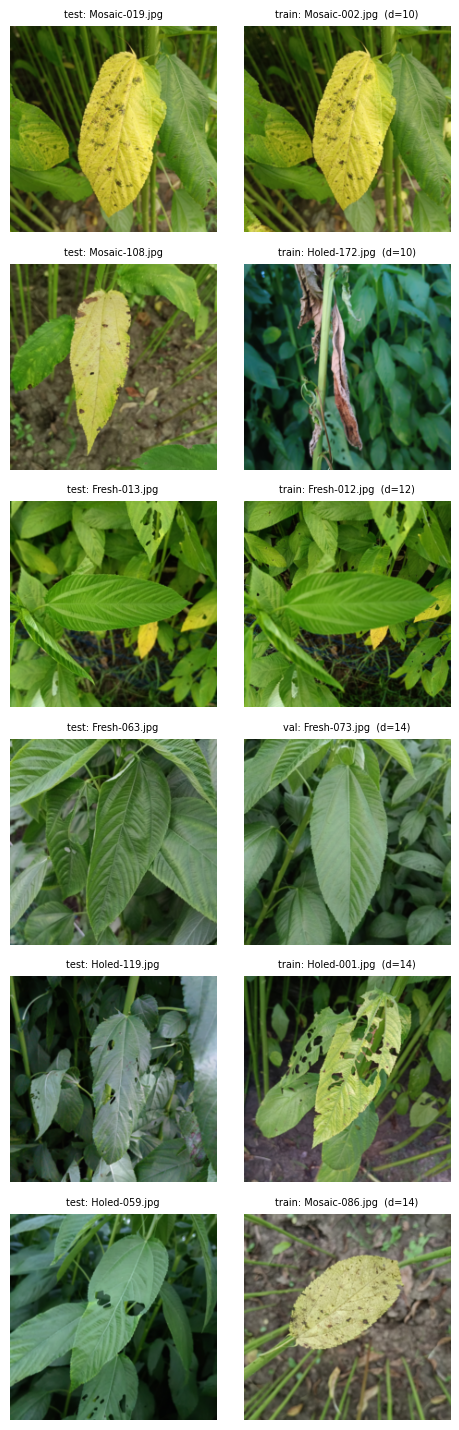


  remove test imgs with d <=  n test left                          Model Acc % (mean±std over seeds)
                          4          139                 Plain ViT-B/16                97.84 ± 0.00
                          4          139 Hybrid (ViT + token attn, r=4)                98.42 ± 0.32
                          4          139                      Swin-Tiny                98.99 ± 0.39
                          4          139                 EfficientNetB0                98.56 ± 0.51
                          8          139                 Plain ViT-B/16                97.84 ± 0.00
                          8          139 Hybrid (ViT + token attn, r=4)                98.42 ± 0.32
                          8          139                      Swin-Tiny                98.99 ± 0.39
                          8          139                 EfficientNetB0                98.56 ± 0.51
                         10          137                 Plain ViT-B/16                97.81 ± 0.0

In [16]:
all_paths = split_df["full_path"].values; split_arr = split_df["split"].values
bits = np.stack([phash64(p) for p in tqdm(all_paths, desc="pHash")])
Hm = hamming_matrix(bits); np.fill_diagonal(Hm, 99)

md5 = [hashlib.md5(open(p, "rb").read()).hexdigest() for p in all_paths]
n_exact = len(md5) - len(set(md5))
print(f"files: {len(all_paths)} | byte-identical duplicate files: {n_exact}")

idx_test = np.where(split_arr == "test")[0]; idx_val = np.where(split_arr == "val")[0]
idx_train = np.where(split_arr == "train")[0]; idx_trval = np.where(split_arr != "test")[0]
nn_test = Hm[np.ix_(idx_test, idx_trval)].min(1)          # aligned with X_test order
nn_val  = Hm[np.ix_(idx_val, idx_train)].min(1)
iu = np.triu_indices(len(all_paths), 1)
rows = []
for T in (0, 2, 4, 6, 8, 10):
    cross = ((Hm[iu] <= T) & (split_arr[iu[0]] != split_arr[iu[1]])).sum()
    allp = (Hm[iu] <= T).sum()
    rows.append({"Hamming <=": T, "test imgs with a train/val near-dup": int((nn_test <= T).sum()),
                 "% of test": round(100 * (nn_test <= T).mean(), 1), "val imgs with a train near-dup": int((nn_val <= T).sum()),
                 "near-dup pairs (all)": int(allp), "of which cross-split": int(cross)})
dup_df = pd.DataFrame(rows); print(dup_df.to_string(index=False))
print(f"nearest-neighbour distance of test images: min {nn_test.min()}, median {np.median(nn_test):.0f}")
dup_df.to_csv(f"{TAB_DIR}/table_duplicates.csv", index=False)

# panel with the closest test-train pairs
order = np.argsort(nn_test)[:6]
fig, axes = plt.subplots(len(order), 2, figsize=(5, 2.4 * len(order)))
for r, t in enumerate(order):
    gi = idx_test[t]; gj = idx_trval[int(np.argmin(Hm[gi, idx_trval]))]
    for c, g in enumerate((gi, gj)):
        axes[r, c].imshow(IMG_CACHE[all_paths[g]].permute(1, 2, 0).numpy()); axes[r, c].axis("off")
        axes[r, c].set_title(("test: " if c == 0 else f"{split_arr[g]}: ") + os.path.basename(all_paths[g]) + (f"  (d={nn_test[t]})" if c == 1 else ""), fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/nearest_test_train_pairs.png", dpi=200); plt.show()

# does accuracy survive when near-duplicate test images are removed?
rows = []
for T in (4, 8, 10):
    keep = nn_test > T
    for tag in MAIN_MODELS:
        accs = np.array([(RUNS[(tag, s)]["preds"][keep] == RUNS[(tag, s)]["lbls"][keep]).mean() * 100 for s in SEEDS if (tag, s) in RUNS])
        rows.append({"remove test imgs with d <=": T, "n test left": int(keep.sum()), "Model": DISPLAY[tag],
                     "Acc % (mean±std over seeds)": fmt_ms(accs.mean(), accs.std(ddof=1) if len(accs) > 1 else 0.0)})
filt_df = pd.DataFrame(rows); print("\n", filt_df.to_string(index=False))
filt_df.to_csv(f"{TAB_DIR}/table_accuracy_after_dedup.csv", index=False)

## 8. Interpretability: Grad-CAM for plain ViT vs hybrid, quantified on **all 139 test images**
Both models use the identical setup: Grad-CAM at the last encoder block's `layernorm_before` (14x14 patch tokens, CLS dropped), target = the model's own predicted class, seed-42 checkpoint.
Metrics (no annotation needed): **deletion / insertion AUC** (does removing / revealing the highlighted pixels change the prediction? lower deletion, higher insertion = more faithful) and **concentration** (share of heat in the top 10 % of pixels, normalised entropy).
If `ANNOT_DIR` is set, **overlap with your lesion annotations** is added.

In [17]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

def vit_of(model): return model.vit if hasattr(model, "vit") else model.backbone
def vit_reshape(t, h=14, w=14):
    r = t[:, 1:, :].reshape(t.size(0), h, w, t.size(2)); return r.permute(0, 3, 1, 2)

def compute_cams(model, imgs, bs=16):
    cam = GradCAM(model=model, target_layers=[vit_of(model).encoder.layer[-1].layernorm_before], reshape_transform=vit_reshape)
    out, cls = [], []
    for i in range(0, len(imgs), bs):
        x = imgs[i:i + bs].to(device)
        with torch.no_grad(): c = model(x).argmax(1).cpu().numpy()
        out.append(cam(input_tensor=x, targets=[ClassifierOutputTarget(int(k)) for k in c])); cls.append(c)
    cam.activations_and_grads.release()
    return np.concatenate(out), np.concatenate(cls)

@torch.no_grad()
def faithfulness(model, imgs, cams, cls, steps=20):
    blurred = TF.gaussian_blur(imgs, kernel_size=51, sigma=20.0)
    ad, ai = [], []
    for i in range(len(imgs)):
        fr, masks = topk_masks(cams[i], steps, seed=i)
        m = torch.from_numpy(masks).float().unsqueeze(1)
        img, bl = imgs[i:i + 1], blurred[i:i + 1]
        batch = torch.cat([img * (1 - m) + bl * m, bl * (1 - m) + img * m]).to(device)      # deletion curve, insertion curve
        with torch.autocast("cuda", dtype=torch.float16, enabled=AMP_ON):
            out = model(batch)
        pr = torch.softmax(out.float(), 1)[:, int(cls[i])].cpu().numpy(); n = steps + 1
        ad.append(trapezoid(pr[:n], fr)); ai.append(trapezoid(pr[n:], fr))
    return np.array(ad), np.array(ai)

CAM_MODELS = ["plainvit", "lightattn"]
LOC = {}
for tag in CAM_MODELS:
    mdl = load_trained(tag, SEEDS[0])
    cams, cls = compute_cams(mdl, TEST_IMGS)
    d_auc, i_auc = faithfulness(mdl, TEST_IMGS, cams, cls)
    conc = np.array([cam_concentration(c) for c in cams])
    LOC[tag] = dict(cams=cams, cls=cls, deletion_auc=d_auc, insertion_auc=i_auc, top10_mass=conc[:, 0], entropy=conc[:, 1])
    del mdl; torch.cuda.empty_cache()

METRICS = [("deletion_auc", "Deletion AUC (lower = more faithful)"), ("insertion_auc", "Insertion AUC (higher = more faithful)"),
           ("top10_mass", "Heat share in top-10% pixels (higher = tighter)"), ("entropy", "Normalised entropy (lower = tighter)")]
rows = []
for k, label in METRICS:
    a, b = LOC["plainvit"][k], LOC["lightattn"][k]; d = b - a; lo, hi = boot_ci(d)
    rows.append({"Metric": label, "Plain ViT": fmt_ms(a.mean(), a.std(ddof=1), 3), "Hybrid": fmt_ms(b.mean(), b.std(ddof=1), 3),
                 "Δ (hybrid-plain)": f"{d.mean():+.3f}", "95% bootstrap CI of Δ": f"[{lo:+.3f}, {hi:+.3f}]",
                 "Wilcoxon p": round(paired_wilcoxon(a, b), 4), "N": len(d)})
loc_df = pd.DataFrame(rows); print(loc_df.to_string(index=False))
loc_df.to_csv(f"{TAB_DIR}/table_localization_full_testset.csv", index=False)
print("\nIf the CI of a difference contains 0, report 'no measurable difference' for that metric. That is a valid, honest result.")

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

                                         Metric     Plain ViT        Hybrid Δ (hybrid-plain) 95% bootstrap CI of Δ  Wilcoxon p   N
           Deletion AUC (lower = more faithful) 0.604 ± 0.167 0.496 ± 0.181           -0.107      [-0.132, -0.083]      0.0000 139
         Insertion AUC (higher = more faithful) 0.592 ± 0.162 0.580 ± 0.141           -0.012      [-0.039, +0.014]      0.5200 139
Heat share in top-10% pixels (higher = tighter) 0.428 ± 0.223 0.338 ± 0.142           -0.091      [-0.138, -0.045]      0.0032 139
           Normalised entropy (lower = tighter) 0.922 ± 0.063 0.949 ± 0.036           +0.027      [+0.014, +0.040]      0.0009 139

If the CI of a difference contains 0, report 'no measurable difference' for that metric. That is a valid, honest result.


In [18]:
# ---- overlap with lesion annotations (only if ANNOT_DIR is set and contains LabelMe .json files) ---------------------
ANN = {}
if ANNOT_DIR and os.path.isdir(ANNOT_DIR):
    for i, p in enumerate(X_test):
        jp = os.path.join(ANNOT_DIR, os.path.splitext(os.path.basename(p))[0] + ".json")
        if os.path.exists(jp):
            ANN[i] = labelme_mask(jp, IMG_SIZE)
    print(f"annotations found for {len(ANN)} test images")
else:
    print("ANNOT_DIR not set / not found -> annotation-based metrics skipped (everything else is unaffected).")

if ANN:
    idxs = sorted(ANN); out = {}
    for tag in CAM_MODELS:
        m = np.array([cam_vs_mask(LOC[tag]["cams"][i], ANN[i]) for i in idxs]); out[tag] = m
    rows = []
    for j, label in enumerate(["CAM mass inside lesion", "Pointing-game hit rate", "Lift (mass share / area share)"]):
        a, b = out["plainvit"][:, j], out["lightattn"][:, j]; d = b - a; lo, hi = boot_ci(d)
        rows.append({"Metric": label, "Plain ViT": f"{a.mean():.3f}", "Hybrid": f"{b.mean():.3f}", "Δ": f"{d.mean():+.3f}",
                     "95% bootstrap CI of Δ": f"[{lo:+.3f}, {hi:+.3f}]", "N annotated": len(idxs)})
    ann_df = pd.DataFrame(rows); print(ann_df.to_string(index=False))
    ann_df.to_csv(f"{TAB_DIR}/table_localization_annotated.csv", index=False)
    print("N is small: describe these as supporting evidence on an annotated subset, not as a significance test.")

annotations found for 23 test images
                        Metric Plain ViT Hybrid      Δ 95% bootstrap CI of Δ  N annotated
        CAM mass inside lesion     0.154  0.192 +0.038      [-0.025, +0.102]           23
        Pointing-game hit rate     0.130  0.174 +0.043      [-0.130, +0.217]           23
Lift (mass share / area share)     1.042  1.440 +0.398      [-0.041, +0.863]           23
N is small: describe these as supporting evidence on an annotated subset, not as a significance test.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

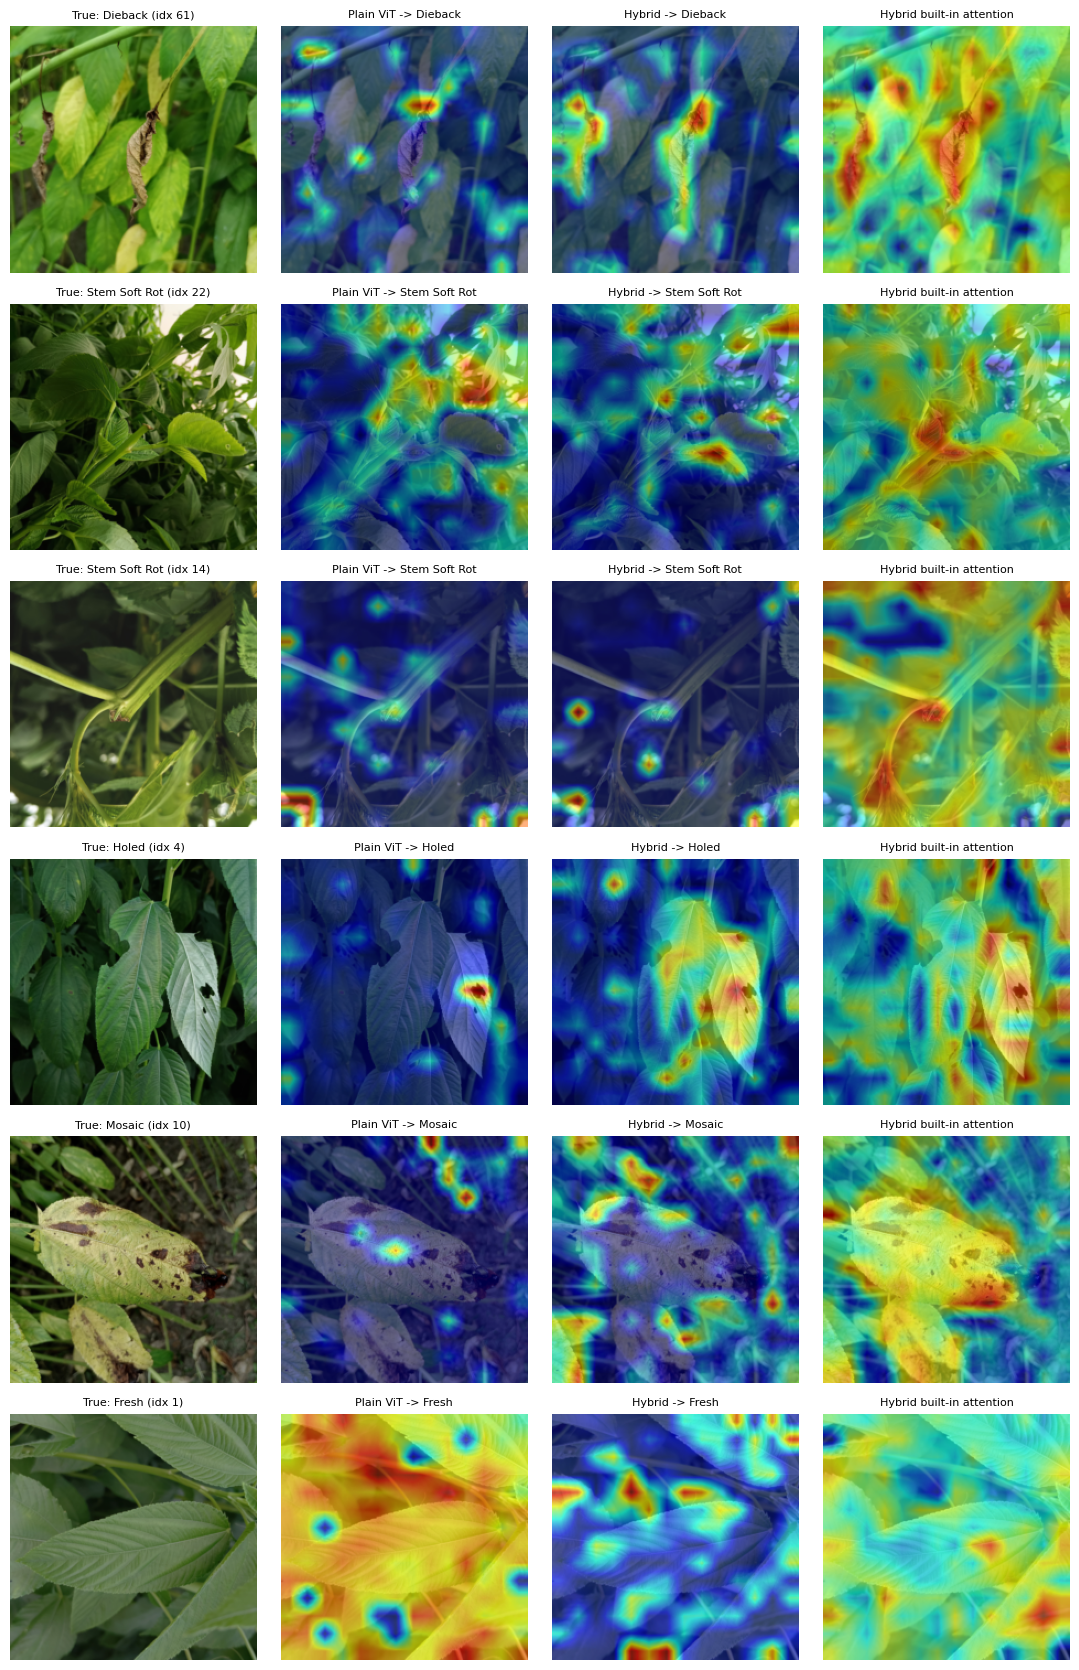

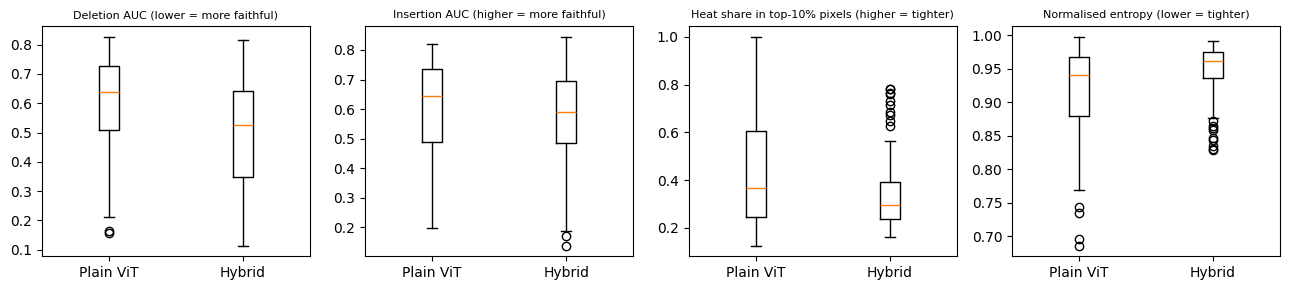

In [19]:
# ---- figures: Grad-CAM comparison (same 4 images as the submitted Fig. 4 + one Mosaic + one Fresh) ------------------
SHOW = [61, 22, 14, 4, 10, 1]
EXPECT = {61: "Dieback", 22: "Stem Soft Rot", 14: "Stem Soft Rot", 4: "Holed"}
for i, name in EXPECT.items():
    if classes[int(y_test[i])] != name:
        print(f"WARNING: test index {i} is '{classes[int(y_test[i])]}', the submitted Fig.4 says '{name}' -> index order differs from your Grad-CAM notebook")

mdl_h = load_trained("lightattn", SEEDS[0])
with torch.no_grad():
    mdl_h(TEST_IMGS[SHOW].to(device)); aw = mdl_h.light_attn.last_attn_weights[:, 0, 1:].reshape(-1, 1, 14, 14).float()
    aw = F.interpolate(aw, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[:, 0].cpu().numpy()
del mdl_h; torch.cuda.empty_cache()
aw = (aw - aw.min((1, 2), keepdims=True)) / (aw.max((1, 2), keepdims=True) - aw.min((1, 2), keepdims=True) + 1e-9)

fig, axes = plt.subplots(len(SHOW), 4, figsize=(11, 2.8 * len(SHOW)))
for r, i in enumerate(SHOW):
    rgb = TEST_IMGS[i].permute(1, 2, 0).numpy()
    panels = [(rgb, f"True: {classes[int(y_test[i])]} (idx {i})"),
              (show_cam_on_image(rgb, LOC["plainvit"]["cams"][i], use_rgb=True), f"Plain ViT -> {classes[int(LOC['plainvit']['cls'][i])]}"),
              (show_cam_on_image(rgb, LOC["lightattn"]["cams"][i], use_rgb=True), f"Hybrid -> {classes[int(LOC['lightattn']['cls'][i])]}"),
              (show_cam_on_image(rgb, aw[r], use_rgb=True), "Hybrid built-in attention")]
    for c, (im, t) in enumerate(panels):
        axes[r, c].imshow(im); axes[r, c].set_title(t, fontsize=8); axes[r, c].axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_gradcam_comparison.png", dpi=250); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, (k, label) in zip(axes, METRICS):
    ax.boxplot([LOC["plainvit"][k], LOC["lightattn"][k]]); ax.set_xticklabels(["Plain ViT", "Hybrid"]); ax.set_title(label, fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_localization_metrics.png", dpi=250); plt.show()

## 9. Ablation of the attention module (answers the novelty comments)
Does the cheap reduced-width attention behave differently from a full-width extra attention layer, other reduction ratios, or an SE-style gate? Single seed by default (`ABLATION_SEEDS`): **report it as single-seed**, or add seeds.

In [20]:
if RUN_ABLATION:
    for seed in ABLATION_SEEDS:
        for tag in ABLATION_VARIANTS:
            RUNS[(tag, seed)] = run_experiment(tag, seed)
    PARAMS_ABL = {}
    for tag in ["plainvit", "lightattn"] + ABLATION_VARIANTS:
        m = ALL_BUILDERS[tag](42); PARAMS_ABL[tag] = sum(p.numel() for p in m.parameters()) / 1e6; del m
    torch.cuda.empty_cache()
    rows = []
    for tag in ["plainvit", "lightattn"] + ABLATION_VARIANTS:
        rr = [RUNS[(tag, s)]["metrics"] for s in ABLATION_SEEDS if (tag, s) in RUNS]
        a = np.array([r["accuracy"] for r in rr]) * 100; f = np.array([r["f1_macro"] for r in rr]) * 100
        rows.append({"Variant": DISPLAY[tag], "Params (M)": round(PARAMS_ABL[tag], 2), "Added vs plain ViT (M)": round(PARAMS_ABL[tag] - PARAMS_ABL["plainvit"], 3),
                     "Seeds": len(rr), "Acc %": fmt_ms(a.mean(), a.std(ddof=1) if len(a) > 1 else 0.0), "Macro-F1 %": fmt_ms(f.mean(), f.std(ddof=1) if len(f) > 1 else 0.0)})
    abl_df = pd.DataFrame(rows); print(abl_df.to_string(index=False)); abl_df.to_csv(f"{TAB_DIR}/table_ablation.csv", index=False)
else:
    print("RUN_ABLATION = False")

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[abl_fullwidth_r1_seed42] ep   1 | train loss 1.0244 acc 0.6978 | val loss 0.5656 acc 0.9424
[abl_fullwidth_r1_seed42] ep   2 | train loss 0.5302 acc 0.9517 | val loss 0.4933 acc 0.9604
[abl_fullwidth_r1_seed42] ep   3 | train loss 0.4761 acc 0.9743 | val loss 0.4748 acc 0.9676
[abl_fullwidth_r1_seed42] ep   4 | train loss 0.4359 acc 0.9897 | val loss 0.4525 acc 0.9784
[abl_fullwidth_r1_seed42] ep   5 | train loss 0.4201 acc 0.9990 | val loss 0.4498 acc 0.9820
[abl_fullwidth_r1_seed42] ep   6 | train loss 0.4152 acc 0.9979 | val loss 0.4391 acc 0.9784
[abl_fullwidth_r1_seed42] ep   7 | train loss 0.4084 acc 0.9969 | val loss 0.4386 acc 0.9820
[abl_fullwidth_r1_seed42] ep   8 | train loss 0.4032 acc 1.0000 | val loss 0.4354 acc 0.9784
[abl_fullwidth_r1_seed42] ep   9 | train loss 0.4026 acc 1.0000 | val loss 0.4356 acc 0.9820
[abl_fullwidth_r1_seed42] ep  10 | train loss 0.4007 acc 1.0000 | val loss 0.4324 acc 0.9820
[abl_fullwidth_r1_seed42] ep  11 | train loss 0.3995 acc 1.0000 | val 

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[abl_r2_seed42] ep   1 | train loss 1.0884 acc 0.6598 | val loss 0.5971 acc 0.9209
[abl_r2_seed42] ep   2 | train loss 0.5377 acc 0.9466 | val loss 0.4970 acc 0.9640
[abl_r2_seed42] ep   3 | train loss 0.4798 acc 0.9723 | val loss 0.4880 acc 0.9748
[abl_r2_seed42] ep   4 | train loss 0.4419 acc 0.9887 | val loss 0.4607 acc 0.9820
[abl_r2_seed42] ep   5 | train loss 0.4258 acc 0.9938 | val loss 0.4586 acc 0.9856
[abl_r2_seed42] ep   6 | train loss 0.4123 acc 0.9990 | val loss 0.4519 acc 0.9748
[abl_r2_seed42] ep   7 | train loss 0.4086 acc 1.0000 | val loss 0.4460 acc 0.9856
[abl_r2_seed42] ep   8 | train loss 0.4059 acc 0.9990 | val loss 0.4468 acc 0.9856
[abl_r2_seed42] ep   9 | train loss 0.4030 acc 1.0000 | val loss 0.4434 acc 0.9820
[abl_r2_seed42] ep  10 | train loss 0.4007 acc 1.0000 | val loss 0.4409 acc 0.9856
[abl_r2_seed42] ep  11 | train loss 0.4015 acc 0.9990 | val loss 0.4392 acc 0.9892
[abl_r2_seed42] ep  12 | train loss 0.3995 acc 1.0000 | val loss 0.4396 acc 0.9856
[abl

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[abl_r8_seed42] ep   1 | train loss 0.9099 acc 0.7739 | val loss 0.5380 acc 0.9496
[abl_r8_seed42] ep   2 | train loss 0.5150 acc 0.9548 | val loss 0.4837 acc 0.9712
[abl_r8_seed42] ep   3 | train loss 0.4681 acc 0.9712 | val loss 0.4861 acc 0.9712
[abl_r8_seed42] ep   4 | train loss 0.4336 acc 0.9928 | val loss 0.4502 acc 0.9784
[abl_r8_seed42] ep   5 | train loss 0.4213 acc 0.9938 | val loss 0.4561 acc 0.9712
[abl_r8_seed42] ep   6 | train loss 0.4097 acc 0.9990 | val loss 0.4386 acc 0.9784
[abl_r8_seed42] ep   7 | train loss 0.4068 acc 0.9990 | val loss 0.4423 acc 0.9712
[abl_r8_seed42] ep   8 | train loss 0.4027 acc 1.0000 | val loss 0.4320 acc 0.9784
[abl_r8_seed42] ep   9 | train loss 0.4019 acc 1.0000 | val loss 0.4335 acc 0.9748
[abl_r8_seed42] ep  10 | train loss 0.3998 acc 1.0000 | val loss 0.4341 acc 0.9784
[abl_r8_seed42] ep  11 | train loss 0.3992 acc 1.0000 | val loss 0.4315 acc 0.9784
[abl_r8_seed42] ep  12 | train loss 0.3986 acc 1.0000 | val loss 0.4305 acc 0.9784
[abl

... (21 outputs left out)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

                       Variant  Params (M)  Added vs plain ViT (M)  Seeds        Acc %   Macro-F1 %
                Plain ViT-B/16       86.39                   0.000      3 97.84 ± 0.00 97.87 ± 0.05
Hybrid (ViT + token attn, r=4)       87.28                   0.887      3 98.32 ± 0.42 98.37 ± 0.40
   ViT + full-width attn (r=1)       88.17                   1.773      3 97.84 ± 0.72 97.92 ± 0.70
                    Hybrid r=2       87.58                   1.183      3 96.88 ± 0.83 96.91 ± 0.87
                    Hybrid r=8       87.13                   0.740      3 98.32 ± 1.10 98.35 ± 1.09
           ViT + SE-style gate       86.69                   0.297      3 98.32 ± 0.83 98.37 ± 0.82


## 10. Optional: stratified k-fold cross-validation (`RUN_CV = True`)
Pools train+val+test (1,390 images), 5 folds, one seed (42) per fold, ~12% of each training fold held out for early stopping. Every image is tested exactly once. This adds 4 x 5 training runs, so only enable it if time allows (a second session is fine: runs are cached).

In [21]:
if RUN_CV:
    from sklearn.model_selection import StratifiedKFold
    from functools import partial
    Xa, ya = split_df["full_path"].values, split_df["label"].values.astype(int)
    skf = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=42)
    folds = list(skf.split(Xa, ya)); CV = {}
    for k, (tr, te) in enumerate(folds):
        a, v = train_test_split(np.arange(len(tr)), test_size=0.12, stratify=ya[tr], random_state=42)
        fn = partial(lambda seed, tr=tr, a=a, v=v, te=te: make_loaders(Xa[tr][a], ya[tr][a], Xa[tr][v], ya[tr][v], Xa[te], ya[te], seed))
        for tag in MAIN_MODELS:
            CV[(tag, k)] = run_experiment(tag, 42, loaders_fn=fn, run_name=f"cv_{tag}_fold{k}", keep=False)
    rows, pooled = [], {}
    for tag in MAIN_MODELS:
        accs = np.array([CV[(tag, k)]["metrics"]["accuracy"] for k in range(CV_FOLDS)]) * 100
        f1s = np.array([CV[(tag, k)]["metrics"]["f1_macro"] for k in range(CV_FOLDS)]) * 100
        c = np.zeros(len(Xa), bool)
        for k, (tr, te) in enumerate(folds): c[te] = CV[(tag, k)]["preds"] == CV[(tag, k)]["lbls"]
        pooled[tag] = c; lo, hi = wilson_ci(int(c.sum()), len(c))
        rows.append({"Model": DISPLAY[tag], "Acc % (mean±std over folds)": fmt_ms(accs.mean(), accs.std(ddof=1)), "Macro-F1 %": fmt_ms(f1s.mean(), f1s.std(ddof=1)),
                     "Pooled acc %": round(100 * c.mean(), 2), "Pooled 95% Wilson CI": f"[{100*lo:.2f}, {100*hi:.2f}]"})
    cv_df = pd.DataFrame(rows); print(cv_df.to_string(index=False)); cv_df.to_csv(f"{TAB_DIR}/table_cv.csv", index=False)
    rows = []
    for a_, b_ in itertools.combinations(MAIN_MODELS, 2):
        na, nb, p = mcnemar_exact(pooled[a_], pooled[b_]); rows.append(dict(model_A=DISPLAY[a_], model_B=DISPLAY[b_], only_A_right=na, only_B_right=nb, p=p))
    cvm = pd.DataFrame(rows); cvm["p_Holm"] = holm(cvm["p"].values); print(cvm.round(4).to_string(index=False)); cvm.to_csv(f"{TAB_DIR}/table_cv_mcnemar.csv", index=False)
else:
    print("RUN_CV = False (set True in section 0 to run cross-validation)")

RUN_CV = False (set True in section 0 to run cross-validation)


## 11. Figures for the paper (regenerated from the NEW runs, so numbers and figures agree) and export

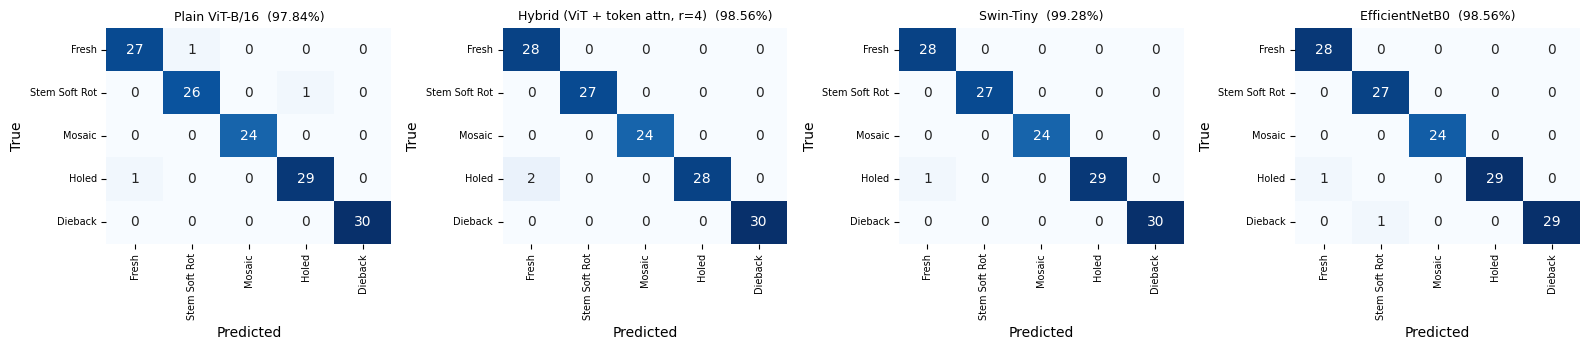

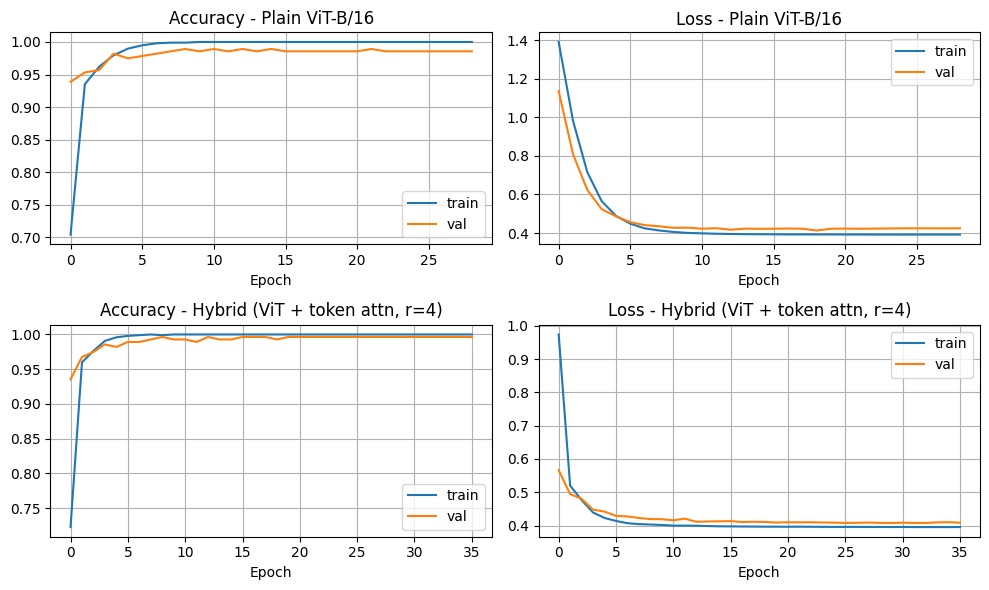

In [22]:
# Fig. 2 style: confusion matrices of the four models (first seed)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, tag in zip(axes, MAIN_MODELS):
    r = RUNS[(tag, SEEDS[0])]; cm = confusion_matrix(r["lbls"], r["preds"], labels=range(len(classes)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=classes, yticklabels=classes, ax=ax)
    ax.set_title(f"{DISPLAY[tag]}  ({r['metrics']['accuracy']*100:.2f}%)", fontsize=9); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.tick_params(labelsize=7)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_confusion_matrices.png", dpi=250); plt.show()

# Fig. 3 style: training curves, plain ViT vs hybrid (first seed)
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for r_, tag in enumerate(["plainvit", "lightattn"]):
    h = RUNS[(tag, SEEDS[0])]["history"]
    axes[r_, 0].plot(h["train_acc"], label="train"); axes[r_, 0].plot(h["val_acc"], label="val"); axes[r_, 0].set_title(f"Accuracy - {DISPLAY[tag]}")
    axes[r_, 1].plot(h["train_loss"], label="train"); axes[r_, 1].plot(h["val_loss"], label="val"); axes[r_, 1].set_title(f"Loss - {DISPLAY[tag]}")
    for a_ in axes[r_]: a_.legend(); a_.grid(True); a_.set_xlabel("Epoch")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_training_curves.png", dpi=250); plt.show()

In [23]:
# ---- export everything needed for the paper + the response letter ----------------------------------------------------
import sys, transformers, torchvision
with open(f"{WORK}/environment.txt", "w") as f:
    f.write(f"python {sys.version.split()[0]}\ntorch {torch.__version__}\ntorchvision {torchvision.__version__}\ntransformers {transformers.__version__}\n"
            f"gpu {torch.cuda.get_device_name() if device.type=='cuda' else 'cpu'}\namp {AMP_ON}\nseeds {SEEDS}\n")
cfg = {k: globals()[k] for k in ["SEEDS", "MAIN_MODELS", "MAX_EPOCHS", "LEARNING_RATE", "WEIGHT_DECAY", "BATCH_SIZE", "EARLY_STOP_PATIENCE",
                                 "EARLY_STOP_MIN_DELTA", "IMG_SIZE", "USE_AMP", "ABLATION_SEEDS", "ABLATION_VARIANTS", "RUN_CV", "QUICK_TEST"]}
json.dump(cfg, open(f"{WORK}/config.json", "w"), indent=2)
shutil.copy(SPLIT_CSV, f"{WORK}/dataset_split.csv")

zip_path = shutil.make_archive(f"{WORK}_outputs", "zip", WORK)
print("EXPORT:", zip_path, f"({os.path.getsize(zip_path)/1e6:.1f} MB)  <- download from the Kaggle 'Output' tab")
print("\nTables:", sorted(os.listdir(TAB_DIR))); print("Figures:", sorted(os.listdir(FIG_DIR)))
print("\nDONE. Paste the printed tables back to Claude and we write the paper text + response letter from the real numbers.")

EXPORT: /kaggle/working/jute_revision_outputs.zip (26.8 MB)  <- download from the Kaggle 'Output' tab

Tables: ['all_runs.csv', 'annotation_candidates.csv', 'table_ablation.csv', 'table_accuracy_after_dedup.csv', 'table_cost.csv', 'table_duplicates.csv', 'table_localization_annotated.csv', 'table_localization_full_testset.csv', 'table_main_5seeds.csv', 'table_mcnemar.csv']
Figures: ['fig_confusion_matrices.png', 'fig_gradcam_comparison.png', 'fig_localization_metrics.png', 'fig_training_curves.png', 'nearest_test_train_pairs.png']

DONE. Paste the printed tables back to Claude and we write the paper text + response letter from the real numbers.
